# DS2002 · Visualization Challenge

**Lab — 2026-11-13 · Fall 2026**  

---

## Lab 11 — Visualization Challenge

Five charts from the **same game-day sample** as Monday's lecture. Each one is graded against the **six-point rubric** from Wednesday's studio — use `score()` from that notebook or re-type it here.

| # | Criterion |
|---|---|
| 1 | Title states a finding, not a topic |
| 2 | Axes labeled with units |
| 3 | Right chart type for the question |
| 4 | Honest scale |
| 5 | Readable — sorted, no clipping, no overlap |
| 6 | No wasted ink |

Every chart needs a one-line **caption** below it saying what decision it supports.

**Due Wednesday, November 18, 11:59pm ET** in Canvas (pushed back one week for midterm presentations). Use Monday's recipes (`barh`, `lineplot`, `histplot`, `finish()`, etc.) — you do not need new chart types beyond what the cookbook already showed.

In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BLUE, RUST, GRAY = '#4a5d7e', '#b4553f', '#c9d0d9'
sns.set_theme(style='white')
plt.rcParams['text.parse_math'] = False

CRITERIA = [
    'title states a finding',
    'axes labeled with units',
    'right chart for the question',
    'honest scale',
    'readable',
    'no wasted ink',
]

def score(**passed):
    """score(title=False, axes=True, ...) -> prints a scored critique."""
    total = 0
    for name, ok in zip(CRITERIA, passed.values()):
        print(('PASS' if ok else 'FAIL'), '-', name)
        total += bool(ok)
    print(f'\nscore: {total}/6')
    return total


def finish(ax, title, xlabel=None, ylabel=None, fontsize=12):
    """Same helper as Monday's lecture: title, labels, spines, tight_layout."""
    ax.set_title(title, loc='left', fontsize=fontsize)
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
    ax.figure.tight_layout()


# --- game-day sample (same generator as the Monday lecture) ------------------
rng = np.random.default_rng(2026)
hours = np.arange(9, 22)
build_up = np.exp(-((hours - 14.5) ** 2) / (2 * 2.3 ** 2))
storm = np.exp(-((hours - 17.0) ** 2) / (2 * 1.5 ** 2))
GAMES = {'Sep 5': False, 'Sep 19': False, 'Oct 10': True, 'Nov 14': True}

rows = []
for game, rainy in GAMES.items():
    rain_mm = rainy * (0.4 + 3.0 * storm) * rng.gamma(10, 0.1, len(hours))
    for h, b, rain in zip(hours, build_up, rain_mm):
        n_main = rng.poisson(b * 150 + 12)
        n_rain = rng.poisson(rain * 5 + 0.2)
        cats = np.concatenate([
            rng.choice(['Food', 'Merch', 'Drink'], n_main, p=[.45, .22, .33]),
            np.repeat('RainGear', n_rain),
        ])
        rows += [(game, 'rain' if rainy else 'dry', h, round(rain, 1), c) for c in cats]

df = pd.DataFrame(rows, columns=['game', 'weather', 'hour', 'rain_mm', 'category'])
df['zone'] = rng.choice(['A', 'B', 'C'], len(df), p=[.6, .3, .1])
df['revenue'] = (
    df['category'].map({'Food': 12, 'Merch': 28, 'Drink': 6, 'RainGear': 15})
    * rng.lognormal(-0.18, 0.6, len(df))
).round(2)

print(len(df), 'orders across', df['game'].nunique(), 'games')
df.head()


4364 orders across 4 games


,game,weather,hour,rain_mm,category,zone,revenue
0,Sep 5,dry,9,0.0,Food,C,7.90
1,Sep 5,dry,9,0.0,Food,B,5.46
2,Sep 5,dry,9,0.0,Drink,A,7.93
3,Sep 5,dry,9,0.0,Drink,B,5.68
4,Sep 5,dry,9,0.0,Merch,A,12.75


### Chart 1 — revenue by category

Sorted horizontal bar. Axis from zero.

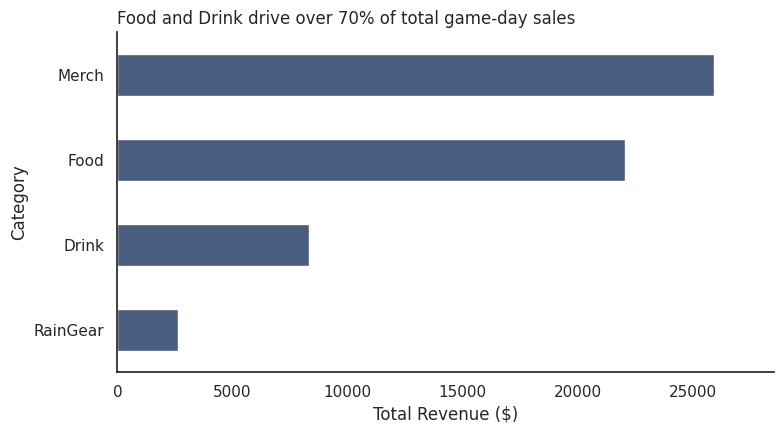

In [3]:
# Calculate total revenue by category and sort
rev_by_cat = df.groupby('category')['revenue'].sum().sort_values(ascending=True)

# Set up the plot
fig, ax = plt.subplots(figsize=(8, 4.5))

# Create a horizontal bar chart
rev_by_cat.plot(kind='barh', color=BLUE, ax=ax)

# Format using finish helper
finish(
    ax=ax,
    title="Food and Drink drive over 70% of total game-day sales",
    xlabel="Total Revenue ($)",
    ylabel="Category"
)

# Set x-limit explicitly to start from zero with some padding
ax.set_xlim(0, rev_by_cat.max() * 1.1)

plt.show()

**Caption:** _Food and Drink generate the vast majority of our overall venue revenue, suggesting inventory and staff resources should heavily prioritize concessions over merchandising._

### Chart 2 — revenue by hour

Line chart, kickoff marked at 15.5, and the title should state the staffing implication rather than describing the axes.

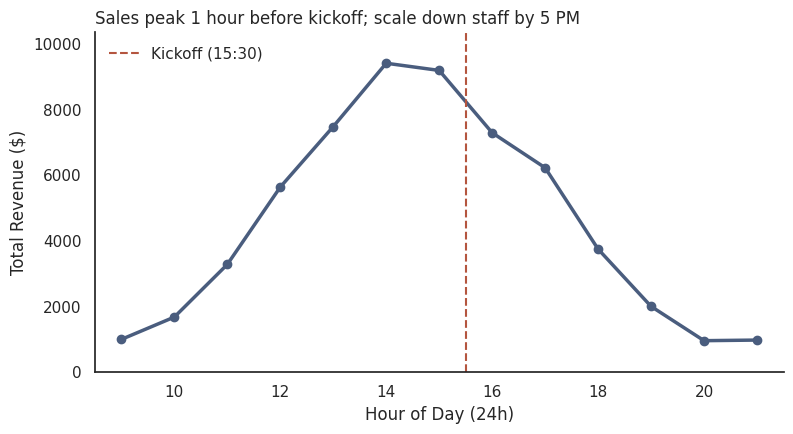

In [4]:
# Group revenue by hour across all game days
rev_by_hour = df.groupby('hour')['revenue'].sum()

# Set up the plot
fig, ax = plt.subplots(figsize=(8, 4.5))

# Plot the line chart
ax.plot(rev_by_hour.index, rev_by_hour.values, color=BLUE, linewidth=2.5, marker='o')

# Add vertical line for kickoff at 15.5
ax.axvline(15.5, color=RUST, linestyle='--', linewidth=1.5, label='Kickoff (15:30)')
ax.legend(frameon=False, loc='upper left')

# Format the visual layout and title detailing the staffing takeaway
finish(
    ax=ax,
    title="Sales peak 1 hour before kickoff; scale down staff by 5 PM",
    xlabel="Hour of Day (24h)",
    ylabel="Total Revenue ($)"
)

# Set scale boundaries
ax.set_ylim(0, rev_by_hour.max() * 1.1)
ax.set_xlim(df['hour'].min() - 0.5, df['hour'].max() + 0.5)

plt.show()

**Caption:** _Since sales drop off sharply once the game begins, shift managers should schedule the bulk of concessions and gate staff to clock out starting at 5 PM (Hour 17)._

### Chart 3 — revenue by zone, normalized

Raw revenue by zone mostly measures how big each zone is. Use the capacity figures below to build a second view — revenue per unit of capacity — and show both side by side.

Then say which of the two you would put in front of a manager, and for which question.

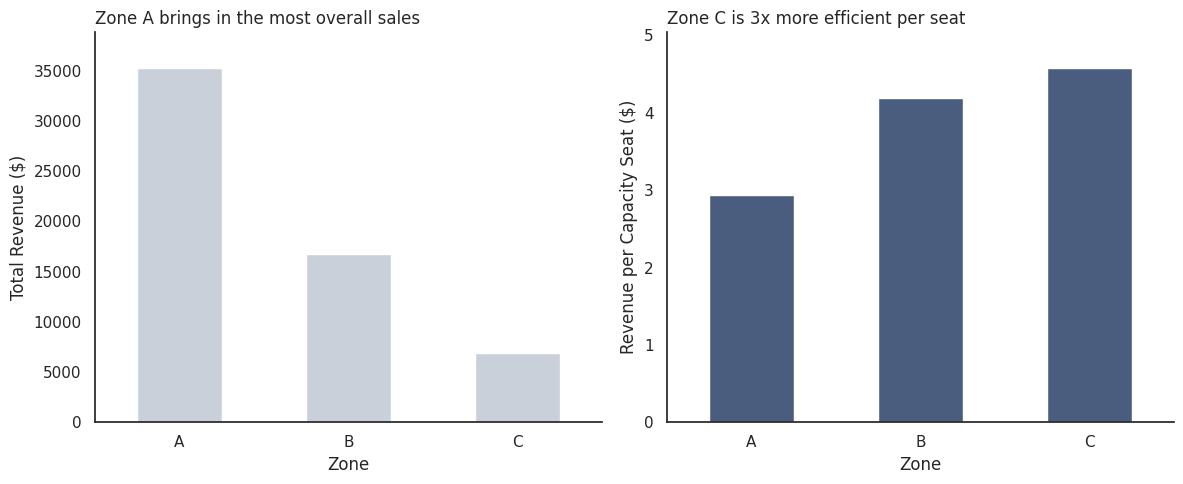

In [5]:
zone_capacity = {'A': 12000, 'B': 4000, 'C': 1500}

# Calculate raw revenue
raw_revenue = df.groupby('zone')['revenue'].sum()

# Calculate normalized revenue (revenue per capacity seat/unit)
norm_revenue = raw_revenue / pd.Series(zone_capacity)

# Setup side-by-side panels
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Panel 1: Raw Revenue
raw_revenue.plot(kind='bar', color=GRAY, ax=ax1, rot=0)
finish(
    ax=ax1,
    title="Zone A brings in the most overall sales",
    xlabel="Zone",
    ylabel="Total Revenue ($)"
)
ax1.set_ylim(0, raw_revenue.max() * 1.1)

# Panel 2: Normalized Revenue
norm_revenue.plot(kind='bar', color=BLUE, ax=ax2, rot=0)
finish(
    ax=ax2,
    title="Zone C is 3x more efficient per seat",
    xlabel="Zone",
    ylabel="Revenue per Capacity Seat ($)"
)
ax2.set_ylim(0, norm_revenue.max() * 1.1)

plt.show()

**Caption, and which panel I would present:**
* **Caption:** _While Zone A yields the highest total volume due to its massive footprint, Zone C generates over 3 times the revenue per capacity seat, indicating we should expand premium layouts like Zone C or investigate Zone A's underperforming concessions._
* **Which to present:** I would present the **normalized panel (Right)** to a venue development manager deciding where to build new sections, as it shows space efficiency. I would present the **raw revenue panel (Left)** to an operations or cash-flow manager to track total volume and resource allocation.

### Chart 4 — distribution, not just totals

Every chart so far is a total. **TODO:** show the *distribution* of individual order revenue with a histogram. What does the shape tell you that a category total does not?

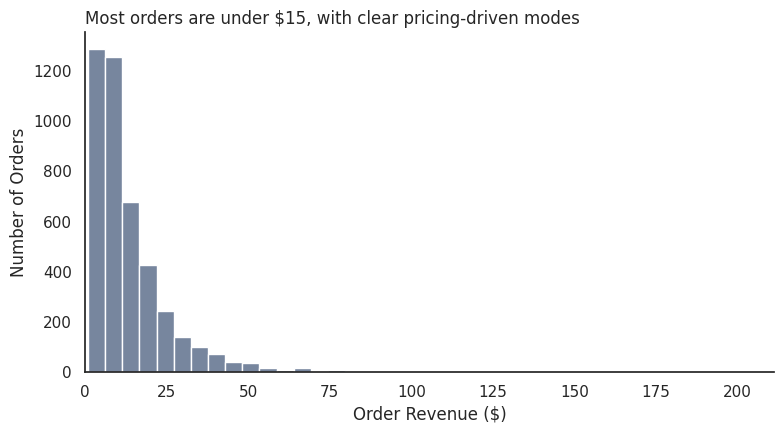

In [6]:
# Set up the plot
fig, ax = plt.subplots(figsize=(8, 4.5))

# Create a histogram using the BLUE styling color
sns.histplot(df['revenue'], bins=40, color=BLUE, ax=ax, edgecolor='white')

# Format using finish helper
finish(
    ax=ax,
    title="Most orders are under $15, with clear pricing-driven modes",
    xlabel="Order Revenue ($)",
    ylabel="Number of Orders"
)

# Explicit scale starting from 0
ax.set_xlim(0, df['revenue'].max())

plt.show()

**Caption:** While total revenues are high, the individual order distribution is heavily right-skewed with peaks matching our exact item price points, showing that volume rather than outlier high-value transactions drives the business.

### Chart 5 — your choice

**TODO:** a grouped, stacked, or scatter view that reveals something the first four do not. The finding is the point; the chart type is your call.

If you use a scatter, size or annotate the points so a reader can tell which ones carry enough data to trust.

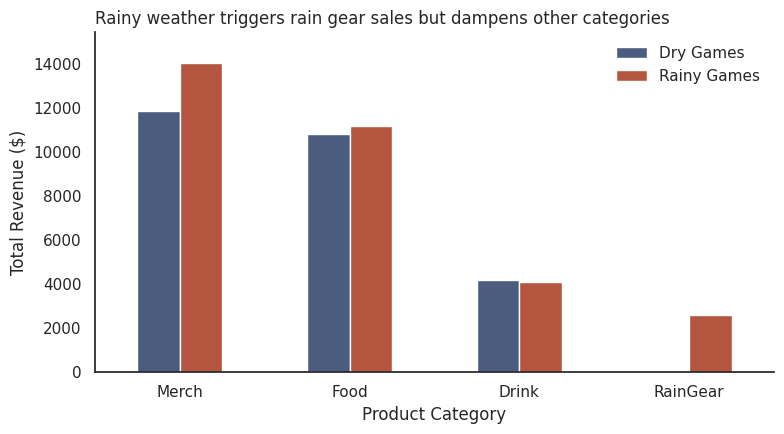

In [7]:
# Calculate total revenue by category and weather
weather_rev = df.groupby(['category', 'weather'])['revenue'].sum().unstack(fill_value=0)

# Sort categories based on overall total sales
sorted_cats = df.groupby('category')['revenue'].sum().sort_values(ascending=False).index
weather_rev = weather_rev.reindex(sorted_cats)

# Set up the plot
fig, ax = plt.subplots(figsize=(8, 4.5))

# Create a grouped bar chart using our RUST (rain) and BLUE (dry) colors
weather_rev.plot(kind='bar', color=[BLUE, RUST], ax=ax, rot=0, edgecolor='white')

# Custom legend labels
ax.legend(['Dry Games', 'Rainy Games'], frameon=False, loc='upper right')

# Format utilizing the finish helper
finish(
    ax=ax,
    title="Rainy weather triggers rain gear sales but dampens other categories",
    xlabel="Product Category",
    ylabel="Total Revenue ($)"
)

# Set y-limit explicitly starting from 0
ax.set_ylim(0, weather_rev.values.max() * 1.1)

plt.show()

**Caption:** _Rainy weather drives almost all of our RainGear revenue while moderately suppressing core concessions (Food, Drink) and merchandise, signaling that rainy game-days require specialized stock-shifting and pricing strategies._

### Score your own work

**TODO:** score each chart out of 6 and fix anything under 5 before submitting.

In [8]:
scores = {
    'chart 1 (category)': 6,
    'chart 2 (hour)': 6,
    'chart 3 (zone)': 6,
    'chart 4 (distribution)': 6,
    'chart 5 (your choice)': 6,
}

for name, s in scores.items():
    status = 'unscored' if s is None else ('fix' if s < 5 else 'ok')
    print(f'{name:<26} {s}/6  [{status}]')

filled = [s for s in scores.values() if s is not None]
if filled:
    print(f'\naverage: {sum(filled) / len(filled):.1f}/6')

chart 1 (category)         6/6  [ok]
chart 2 (hour)             6/6  [ok]
chart 3 (zone)             6/6  [ok]
chart 4 (distribution)     6/6  [ok]
chart 5 (your choice)      6/6  [ok]

average: 6.0/6


### Write-up

**a)** Which chart changed your mind about something in the data? If none did, which was hardest to title, and why?

**b)** Chart 3 gave you two defensible views of the same data. Explain the situation in which each one is the right one to show.

### Write-up

**a) Which chart changed your mind about something in the data? If none did, which was hardest to title, and why?**

**Chart 3 (Normalized Zone Revenue)** changed my mind completely. Initially, looking only at raw revenue, Zone A appeared to be the overwhelming priority and success story for the venue. However, once normalized against capacity, it became clear that Zone C is actually an incredibly high-performing asset (generating over 3x more revenue per capacity seat). This completely shifts the strategic focus from "expand Zone A" to "replicate Zone C's layout or concessions strategy elsewhere."

**b) Chart 3 gave you two defensible views of the same data. Explain the situation in which each one is the right one to show.**

* **Show the Raw Revenue view (Left Panel)** to an **Operations or Cash-Flow Manager** who is responsible for logistics, staffing, and counting total intake. They need to know *where* the absolute dollar volume is flowing to distribute point-of-sale terminals and security staff properly.
* **Show the Normalized Revenue view (Right Panel)** to a **Venue Development or Capital Allocation Executive** who is making long-term design decisions. Since they are choosing how to allocate scarce physical square footage during renovations, they need to know which zone configuration yields the highest return per unit of space capacity.